In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tqdm import tqdm
from skimage.transform import resize

from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

import seaborn as sns

import random
import socket

from tensorflow.keras.applications import MobileNetV3Large
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input

2025-04-29 00:10:39.332720: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1745885439.580287      31 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1745885439.666104      31 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
def check_internet(host="8.8.8.8", port=53, timeout=3):
    """
    checks internet connectivity by attempting to connect to a well-known DNS server.

    Parameters:
        host (str): Host to connect to.
        port (int): Port number.
        timeout (int): Timeout duration in seconds.

    Returns:
        bool: True if connected, False otherwise.
    """
    try:
        socket.setdefaulttimeout(timeout)
        socket.socket(socket.AF_INET, socket.SOCK_STREAM).connect((host, port))
        return True
    except socket.error as ex:
        print(f"Internet connectivity check failed: {ex}")
        return False

internet_available = check_internet()

if not internet_available:
    print("No internet connection detected. The model will be loaded without pre-trained weights.")
else:
    print("Internet connection detected. Proceeding to download pre-trained weights.")

Internet connection detected. Proceeding to download pre-trained weights.


In [3]:
seed = 42
np.random.seed(seed)
tf.random.set_seed(seed)
random.seed(seed)

In [4]:
labels = ['glioma', 'meningioma', 'notumor', 'pituitary']

train_dir = '/kaggle/input/brain-tumor-mri-dataset/Training/'
test_dir = '/kaggle/input/brain-tumor-mri-dataset/Testing/'

In [5]:
import os, hashlib
from collections import defaultdict

def file_sha1(path, chunk=8192):
    h = hashlib.sha1()
    with open(path, 'rb') as f:
        for c in iter(lambda: f.read(chunk), b''):
            h.update(c)
    return h.hexdigest()

def scan_for_duplicates(train_dir, test_dir, *, keep_one_copy=True):
    """
    Parameters
    ----------
    train_dir, test_dir : str
    keep_one_copy       : bool  – keep a single copy (True) or drop *all* copies (False)

    Returns
    -------
    skip_train_paths : set of str – files to ignore when loading training split
    skip_test_paths  : set of str – files to ignore when loading testing split
    stats            : dict       – counters for pretty printing
    """
    buckets = defaultdict(lambda: {'train': [], 'test': []})
    for split, base in (('train', train_dir), ('test', test_dir)):
        for root, _, files in os.walk(base):
            for f in files:
                p   = os.path.join(root, f)
                sha = file_sha1(p)
                buckets[sha][split].append(p)

    skip_train_paths, skip_test_paths = set(), set()
    stats = dict(dup_train=0, dup_test=0, leak_hashes=0,
                 leak_files_train=0, leak_files_test=0)

    for sha, d in buckets.items():
        t_paths = d['train']
        s_paths = d['test']

        # duplicates inside each split
        if len(t_paths) > 1:
            stats['dup_train'] += len(t_paths) - (1 if keep_one_copy else 0)
            skip_train_paths.update(t_paths if not keep_one_copy else t_paths[1:])
        if len(s_paths) > 1:
            stats['dup_test'] += len(s_paths) - (1 if keep_one_copy else 0)
            skip_test_paths.update(s_paths if not keep_one_copy else s_paths[1:])

        # cross-split leakage
        if t_paths and s_paths:
            stats['leak_hashes']      += 1
            stats['leak_files_train'] += len(t_paths) - (0 if keep_one_copy else len(t_paths))
            stats['leak_files_test']  += len(s_paths)
            skip_test_paths.update(s_paths)
            if not keep_one_copy:
                skip_train_paths.update(t_paths)

    return skip_train_paths, skip_test_paths, stats

# run the scan
train_dir = '/kaggle/input/brain-tumor-mri-dataset/Training'
test_dir  = '/kaggle/input/brain-tumor-mri-dataset/Testing'

skip_train_paths, skip_test_paths, st = scan_for_duplicates(
    train_dir, test_dir, keep_one_copy=True
)

print("──────────────────── duplicate / leak report ────────────────────")
print(f"↺ duplicates INSIDE Training : {st['dup_train']}")
print(f"↺ duplicates INSIDE Testing  : {st['dup_test']}")
print(f"↹ leakage across splits      : {st['leak_hashes']} SHA-1s"
      f"  → {st['leak_files_test']} test files skipped")
print("──────────────────────────────────────────────────────────────────")

n_skip_train = len(skip_train_paths)
n_skip_test  = len(skip_test_paths)

──────────────────── duplicate / leak report ────────────────────
↺ duplicates INSIDE Training : 191
↺ duplicates INSIDE Testing  : 27
↹ leakage across splits      : 79 SHA-1s  → 103 test files skipped
──────────────────────────────────────────────────────────────────


In [6]:
# Cell 5 + full pipeline: load_data → preprocess → shuffle → split → encode

import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import resize
from tqdm import tqdm

def load_data(directory, label_list, image_size, *, skip_paths=None, log_skipped=False):
    images, labels_encoded = [], []
    skipped = 0

    for class_idx, label in enumerate(label_list):
        class_dir = os.path.join(directory, label)
        if not os.path.isdir(class_dir):
            if log_skipped:
                print(f"[WARN] '{class_dir}' missing.")
            continue

        for fname in tqdm(os.listdir(class_dir),
                          desc=f"Loading {label} from {os.path.basename(directory)}"):
            img_path = os.path.join(class_dir, fname)
            if skip_paths and img_path in skip_paths:
                skipped += 1
                continue

            try:
                img = plt.imread(img_path)
                # to RGB
                if img.ndim == 2:
                    img = np.stack([img]*3, -1)
                elif img.shape[-1] == 4:
                    img = img[..., :3]
                # scale up if in [0,1]
                if img.max() <= 1.0:
                    img = img * 255.0

                img = img.astype(np.float32)
                img = resize(img, (image_size, image_size, 3), anti_aliasing=True)

                images.append(img)
                labels_encoded.append(class_idx)
            except Exception as e:
                if log_skipped:
                    print(f"[WARN] could not read {img_path}: {e}")

    if log_skipped:
        print(f"Skipped {skipped} file(s) in '{os.path.basename(directory)}'")
    return np.array(images, dtype=np.float32), np.array(labels_encoded), skipped

# parameters
labels     = ['glioma','meningioma','notumor','pituitary']
image_size = 224

# load
print("Loading Training Data…")
X_train, Y_train, skipped_train = load_data(
    train_dir, labels, image_size,
    skip_paths=skip_train_paths, log_skipped=True
)

print("\nLoading Testing Data…")
X_test, Y_test, skipped_test = load_data(
    test_dir, labels, image_size,
    skip_paths=skip_test_paths, log_skipped=True
)

print(f"\n✅ Expected to skip {n_skip_train} train / {n_skip_test} test files.")
print(f"   Actually skipped {skipped_train} train / {skipped_test} test files.")


# MobileNetV3 preprocessing
print("\nApplying MobileNetV3 Preprocessing…")
X_train = preprocess_input(X_train)
X_test  = preprocess_input(X_test)

# shuffle + split
print("\nShuffling Training Data…")
X_train, Y_train = shuffle(X_train, Y_train, random_state=42)

print("Splitting Data into Training and Validation Sets…")
X_train, X_valid, Y_train, Y_valid = train_test_split(
    X_train, Y_train, test_size=0.1, random_state=42, stratify=Y_train
)

# class distributions
for split_name, y in [("Training", Y_train), ("Validation", Y_valid), ("Test", Y_test)]:
    unique, counts = np.unique(y, return_counts=True)
    print(f"\nClass Distribution in {split_name} Set:")
    for lbl, cnt in zip(unique, counts):
        print(f"  {labels[lbl]}: {cnt}")

# one-hot encode
print("\nConverting Labels to Categorical…")
y_train_new = to_categorical(Y_train, num_classes=len(labels))
y_valid_new = to_categorical(Y_valid, num_classes=len(labels))
y_test_new  = to_categorical(Y_test,  num_classes=len(labels))

Loading Training Data…


Loading pituitary from Training: 100%|██████████| 1457/1457 [00:35<00:00, 40.97it/s]


Skipped 191 file(s) in 'Training'

Loading Testing Data…


Loading pituitary from Testing: 100%|██████████| 300/300 [00:06<00:00, 44.56it/s]


Skipped 106 file(s) in 'Testing'

✅ Expected to skip 191 train / 106 test files.
   Actually skipped 191 train / 106 test files.

Applying MobileNetV3 Preprocessing…

Shuffling Training Data…
Splitting Data into Training and Validation Sets…

Class Distribution in Training Set:
  glioma: 1189
  meningioma: 1199
  notumor: 1280
  pituitary: 1300

Class Distribution in Validation Set:
  glioma: 132
  meningioma: 134
  notumor: 142
  pituitary: 145

Class Distribution in Test Set:
  glioma: 299
  meningioma: 302
  notumor: 309
  pituitary: 295

Converting Labels to Categorical…


In [7]:
print("\nSetting Up Data Augmentation...")
datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)
datagen.fit(X_train)
train_generator = datagen.flow(X_train, y_train_new, batch_size=32, shuffle=True)

from sklearn.utils import class_weight
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(Y_train),
    y=Y_train
)
class_weights_dict = {i: class_weights[i] for i in range(len(labels))}
print("\nComputed Class Weights:", class_weights_dict)


Setting Up Data Augmentation...

Computed Class Weights: {0: 1.0445752733389402, 1: 1.035863219349458, 2: 0.9703125, 3: 0.9553846153846154}


In [9]:
print("\nBuilding the Model...")
def build_model(image_size, labels, internet_available):
    try:
        if internet_available:
            base_model = MobileNetV3Large(
                input_shape=(image_size, image_size, 3),
                include_top=False,
                weights='imagenet'
            )
            print("MobileNetV3Large loaded with pre-trained ImageNet weights.")
        else:
            base_model = MobileNetV3Large(
                input_shape=(image_size, image_size, 3),
                include_top=False,
                weights=None
            )
            print("MobileNetV3Large loaded without pre-trained weights.")
    except Exception as e:
        print("Error loading MobileNetV3Large:", e)
        print("Proceeding without pre-trained weights.")
        base_model = MobileNetV3Large(
            input_shape=(image_size, image_size, 3),
            include_top=False,
            weights=None
        )

    for layer in base_model.layers:
        layer.trainable = False

    if internet_available:
        for layer in base_model.layers[-20:]:
            layer.trainable = True
        print("Unfroze the last 20 layers of MobileNetV3Large for fine-tuning.")

    inputs = keras.Input(shape=(image_size, image_size, 3))
    x = base_model(inputs, training=True)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.5)(x)
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.5)(x)
    outputs = Dense(len(labels), activation='softmax')(x)
    model = Model(inputs, outputs)

    print("Compiling the Model...")
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    model.summary()
    return model

model = build_model(image_size, labels, internet_available)


Building the Model...


I0000 00:00:1745885651.147354      31 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1745885651.148105      31 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV3Large loaded with pre-trained ImageNet weights.
Unfroze the last 20 layers of MobileNetV3Large for fine-tuning.
Compiling the Model...


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ MobileNetV3Large (Functional)        │ (None, 7, 7, 960)           │       2,996,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 960)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 960)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         246,016 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │           1,028 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,243,396 (12.37 MB)

 Trainable params: 1,200,244 (4.58 MB)

 Non-trainable params: 2,043,152 (7.79 MB)

In [10]:
print("\nSetting Up Callbacks...")
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
checkpoint = ModelCheckpoint(
    '/kaggle/working/MobileNetV3_Bmodel.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=2e-4, verbose=1)


Setting Up Callbacks...


In [11]:
print("\nStarting Model Training...")
history = model.fit(
    datagen.flow(X_train, y_train_new, batch_size=32),
    epochs=100,
    validation_data=(X_valid, y_valid_new),
    callbacks=[early_stopping, checkpoint, reduce_lr],
    steps_per_epoch=len(X_train) // 32,
    class_weight=class_weights_dict,
    verbose=1
)


Starting Model Training...
Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1745885670.666886      98 service.cc:148] XLA service 0x7eb52e59a7d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1745885670.668115      98 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1745885670.668139      98 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1745885672.111212      98 cuda_dnn.cc:529] Loaded cuDNN version 90300
E0000 00:00:1745885676.236724      98 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing war

  1/155 ━━━━━━━━━━━━━━━━━━━━ 1:05:44 26s/step - accuracy: 0.2812 - loss: 2.3608

I0000 00:00:1745885681.085452      98 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 332ms/step - accuracy: 0.4393 - loss: 1.4272
Epoch 1: val_loss improved from inf to 0.82266, saving model to /kaggle/working/MobileNetV3_Bmodel.keras
155/155 ━━━━━━━━━━━━━━━━━━━━ 87s 401ms/step - accuracy: 0.4401 - loss: 1.4250 - val_accuracy: 0.6166 - val_loss: 0.8227 - learning_rate: 1.0000e-04
Epoch 2/100
  1/155 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.7500 - loss: 0.8271

/usr/lib/python3.11/contextlib.py:158: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)



Epoch 2: val_loss did not improve from 0.82266
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7500 - loss: 0.8271 - val_accuracy: 0.6112 - val_loss: 0.8277 - learning_rate: 1.0000e-04
Epoch 3/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 284ms/step - accuracy: 0.7678 - loss: 0.6027
Epoch 3: val_loss improved from 0.82266 to 0.61408, saving model to /kaggle/working/MobileNetV3_Bmodel.keras
155/155 ━━━━━━━━━━━━━━━━━━━━ 47s 290ms/step - accuracy: 0.7680 - loss: 0.6023 - val_accuracy: 0.7595 - val_loss: 0.6141 - learning_rate: 1.0000e-04
Epoch 4/100
  1/155 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.8125 - loss: 0.6473
Epoch 4: val_loss improved from 0.61408 to 0.61403, saving model to /kaggle/working/MobileNetV3_Bmodel.keras
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8125 - loss: 0.6473 - val_accuracy: 0.7595 - val_loss: 0.6140 - learning_rate: 1.0000e-04
Epoch 5/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 280ms/step - accuracy: 0.8379 - loss: 0.4411
Epoch 5: val_loss improved fro

In [12]:
print("\nLoading the Best Model...")
try:
    model = load_model('/kaggle/working/MobileNetV3_Bmodel.keras')
    print("Best MobileNetV3 model loaded successfully.")
except Exception as e:
    print("Error loading the best model:", e)
    print("Proceeding with the current model weights.")

print("Evaluating the Model on Test Data...")
test_loss, test_accuracy = model.evaluate(X_test, y_test_new, verbose=2)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


Loading the Best Model...
Best MobileNetV3 model loaded successfully.
Evaluating the Model on Test Data...
38/38 - 11s - 301ms/step - accuracy: 0.9768 - loss: 0.0598
Test Accuracy: 97.68%
Test Loss: 0.0598


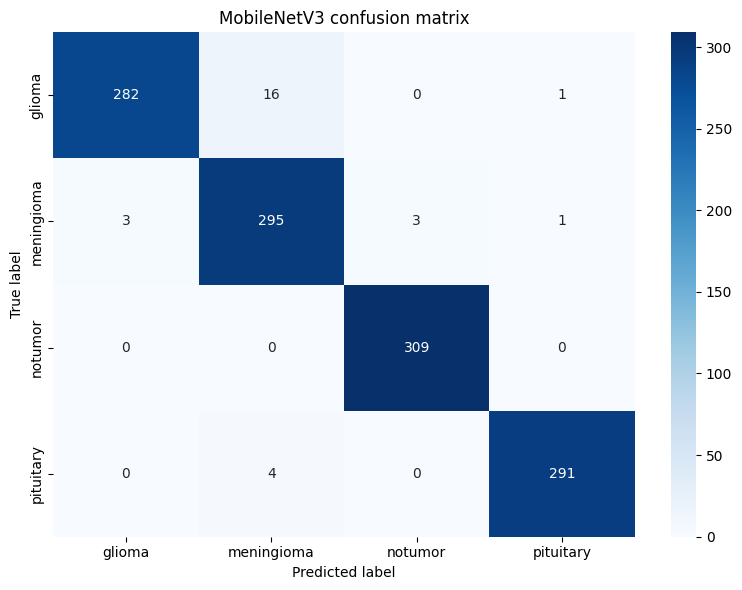

Classification report on test set

              precision    recall  f1-score   support

      glioma     0.9895    0.9431    0.9658       299
  meningioma     0.9365    0.9768    0.9562       302
     notumor     0.9904    1.0000    0.9952       309
   pituitary     0.9932    0.9864    0.9898       295

    accuracy                         0.9768      1205
   macro avg     0.9774    0.9766    0.9767      1205
weighted avg     0.9773    0.9768    0.9768      1205


Overall test accuracy: 97.68%


In [13]:
# 1. get crisp class predictions 
y_prob = model.predict(X_test, verbose=0)          # shape: (N, 4)
y_pred = np.argmax(y_prob, axis=1)                 # -> int labels 0‑3
y_true = np.argmax(y_test_new, axis=1)             # convert 1‑hot back to int

# 2. confusion‑matrix & heat‑map
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm,
            annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('MobileNetV3 confusion matrix')
plt.tight_layout()
plt.show()

# 3. detailed per‑class metrics 
print("Classification report on test set\n")
print(classification_report(y_true, y_pred, target_names=labels, digits=4))

acc = accuracy_score(y_true, y_pred)
print(f"\nOverall test accuracy: {acc*100:.2f}%")

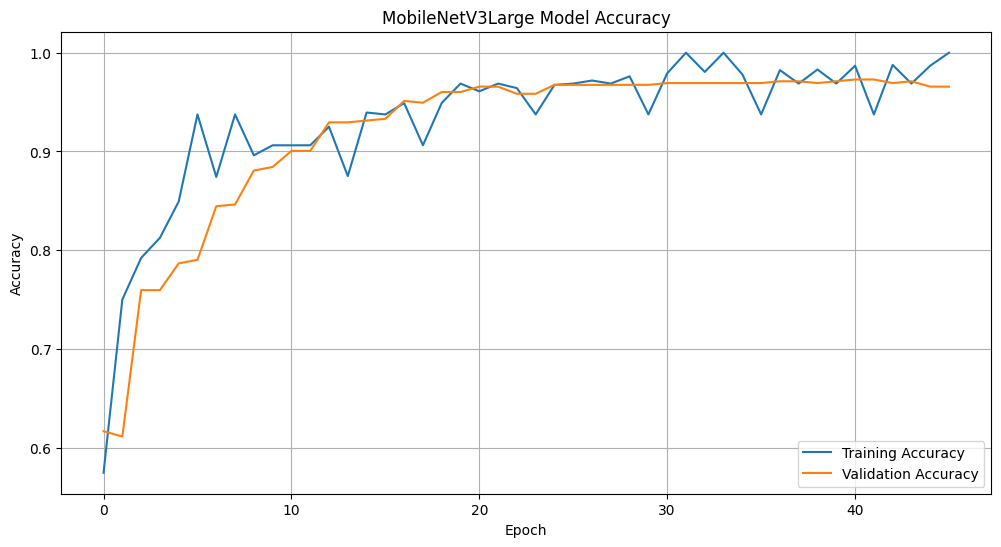

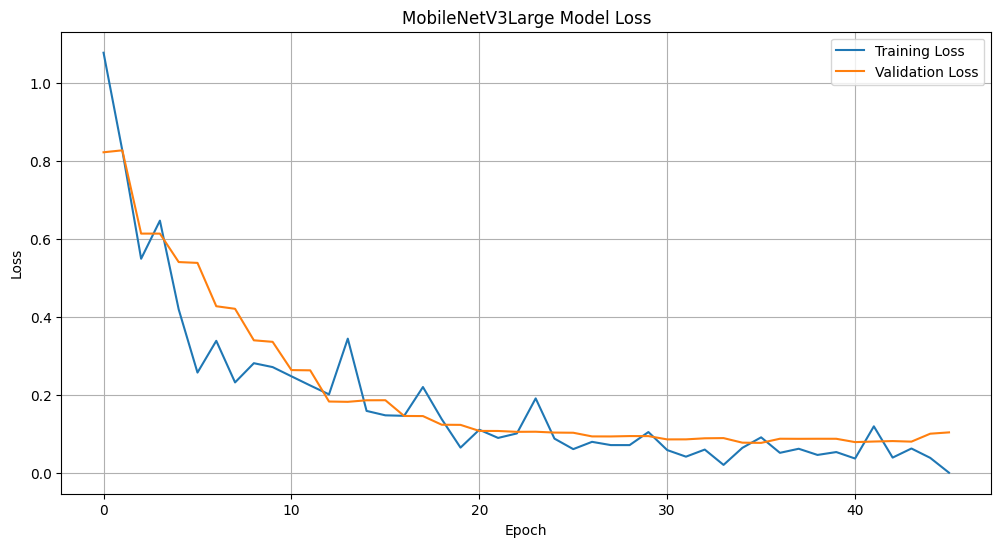

In [14]:
# plot Training and Validation Accuracy
plt.figure(figsize=(12, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('MobileNetV3Large Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# plot Training and Validation Loss
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('MobileNetV3Large Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()